# Data Preparation — BRFSS 2015 Diabetes Dataset

This notebook follows the plan in `MyPlan/data_preparation_plan.md`, step by step.
We start from the raw `2015.csv` (441,456 rows × 330 columns) and finish with a clean dataset, split into `X_train`, `X_test`, `y_train`, `y_test`.

Each step has:
- **Why**: the problem we are looking for
- **Code**: how we check it
- **Result / Decision**: what we found and what we do about it

> **Golden rule:** anything that *learns* from the data (imputer, scaler, SMOTE, feature selection) is fitted **after** the split, on the training set only.
> Before the split we only apply fixed rules that do not depend on the data (decoding codes, dropping columns, fixed value limits).

**One change from the plan:** Step 4 (special codes) is done **before** Step 3 (redundant columns).
Codes like `7`, `9`, `77`, `99` are fake numbers, and they distort the correlations used in Step 3. So we decode them first.

## Step 0 — Setup and load

**Why:** start from an untouched copy (`raw`) so we can always compare "before / after". All changes are made on `df`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)   # show all columns when displaying a DataFrame

raw = pd.read_csv('2015.csv')
df = raw.copy()          # work on df, never modify raw
print(df.shape)

(441456, 330)


## Step 1 — Define the target (`DIABETE3`)

**Why:** everything else depends on what we want to predict. A row without a valid target cannot be used for training.

| Code | Meaning |
|---|---|
| 1 | Yes, diabetes |
| 2 | Yes, but only during pregnancy |
| 3 | No |
| 4 | No, pre-diabetes or borderline |
| 7 | Don't know |
| 9 | Refused |
| NaN | Missing |

`value_counts(dropna=False)` counts each value, **including** `NaN` (normally hidden).

In [2]:
df['DIABETE3'].value_counts(dropna=False)

DIABETE3
3.0    372104
1.0     57256
4.0      7690
2.0      3608
7.0       598
9.0       193
NaN         7
Name: count, dtype: int64

**Decision:**
- Drop the rows with `7`, `9` or `NaN` (about 800 rows, 0.2%: too few to matter).
- Problem type: **3 classes**, as in the README:

| `target` | Meaning | From `DIABETE3` |
|---|---|---|
| 0 | No diabetes | 3 and 2 |
| 1 | Pre-diabetes | 4 |
| 2 | Diabetes | 1 |

- Code `2` (diabetes **only during pregnancy**) goes to "No": gestational diabetes usually disappears after the birth, so these people do not have diabetes now.

`.copy()` after the filter makes `df` a real new table. Without it, pandas shows a `SettingWithCopyWarning` when we add the `target` column.

In [3]:
df = df[df['DIABETE3'].isin([1, 2, 3, 4])].copy()
df['target'] = df['DIABETE3'].map({3: 0, 2: 0, 4: 1, 1: 2}).astype(int)

print(df.shape)
df['target'].value_counts()

(440658, 331)


target
0    375712
2     57256
1      7690
Name: count, dtype: int64

## Step 2 — Select the columns

**Why:** 330 columns is too many. There are 3 kinds of columns we do not want:
1. **Admin / ID columns**: dates, sequence numbers, phone questions, survey weights. They have no medical meaning.
2. **Mostly empty columns**: many questions belong to optional modules asked in only a few states.
3. **Leakage columns**: questions asked **only to diabetic people** (insulin use, age at diagnosis…). The model would "cheat" with them and be useless on new patients.

### 2a — Missing rate per column

In [4]:
missing = df.isna().mean().sort_values(ascending=False)

print((missing > 0.9).sum(), 'columns are more than 90% empty')
print((missing > 0.5).sum(), 'columns are more than 50% empty')
missing.head(15)

102 columns are more than 90% empty
150 columns are more than 50% empty


QLMENTL2    1.000000
QLSTRES2    1.000000
QLHLTH2     1.000000
PAINACT2    1.000000
LADULT      0.999898
COLGHOUS    0.999898
ASDRVIST    0.999292
ASERVIST    0.999290
ASNOSLEP    0.998963
ASTHMED3    0.998550
ASINHALR    0.998550
ASYMPTOM    0.998545
ASACTLIM    0.998539
ASRCHKUP    0.998539
ASATTACK    0.998529
dtype: float64

### 2b — Leakage columns

These come from the diabetes module of the survey and are only answered by people who already have diabetes.

In [5]:
leakage_cols = ['DIABAGE2',   # age when told you have diabetes
                'INSULIN',    # now taking insulin
                'BLDSUGAR',   # how often you check blood sugar
                'FEETCHK2', 'FEETCHK',  # feet checked for sores
                'DOCTDIAB',   # times seen a doctor for diabetes
                'CHKHEMO3',   # times checked for A1C
                'DIABEYE',    # retinopathy
                'DIABEDU',    # took a diabetes course
                'PDIABTST',   # blood sugar test in past 3 years
                'PREDIAB1']   # ever told you have pre-diabetes -> reveals class 1

missing[leakage_cols]

DIABAGE2    0.870074
INSULIN     0.933227
BLDSUGAR    0.933229
FEETCHK2    0.933234
FEETCHK     0.933874
DOCTDIAB    0.933241
CHKHEMO3    0.933243
DIABEYE     0.933245
DIABEDU     0.933245
PDIABTST    0.812689
PREDIAB1    0.812689
dtype: float64

**Result:** all leakage columns are more than 50% empty, so the missing-rate filter removes them anyway. We still drop them **by name** so it stays safe if the threshold changes.

### 2c — Admin / ID columns

In [6]:
admin_cols = ['FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU',
              'CTELENUM', 'PVTRESD1', 'STATERES', 'CELLFON3', 'NUMADULT', 'NUMMEN', 'NUMWOMEN',
              'NUMHHOL2', 'CPDEMO1', 'QSTVER', 'QSTLANG', 'MSCODE', 'PCDMDECN', 'EXACTOT1', 'EXACTOT2',
              '_STSTR', '_STRWT', '_RAWRAKE', '_WT2RAKE', '_CHISPNC', '_DUALUSE', '_DUALCOR', '_LLCPWT']

keep = missing[missing < 0.5].index
df = df[keep].drop(columns=[c for c in admin_cols + leakage_cols if c in keep])
print(df.shape)

(440658, 150)


### 2d — Keep a list of health-related features

About 150 columns are still left. Most are **derived versions** of the same answer (BRFSS stores the raw answer and several computed versions), or detailed lifestyle questions (fruit portions, exercise minutes).

We keep one list of candidate features, grouped by topic. On purpose, it still contains some **pairs that look redundant** (raw answer + computed version). We will check them with data in Step 3 and keep only one of each pair.

In [7]:
features = [
    # body and general health
    '_BMI5', '_BMI5CAT', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'DIFFWALK',
    # blood pressure and cholesterol
    '_RFHYPE5', 'BPHIGH4', 'TOLDHI2', '_RFCHOL', '_CHOLCHK',
    # other chronic diseases
    'CVDSTRK3', '_MICHD', 'CVDINFR4', 'CVDCRHD4', 'CHCKIDNY', 'CHCCOPD1',
    'HAVARTH3', 'ADDEPEV2', 'ASTHMA3',
    # lifestyle
    '_SMOKER3', 'SMOKE100', 'EXERANY2', '_TOTINDA', '_RFDRHV5', '_FRTLT1', '_VEGLT1',
    # access to health care
    'HLTHPLN1', 'MEDCOST',
    # demographics
    'SEX', '_AGEG5YR', '_AGE80', 'EDUCA', '_EDUCAG', 'INCOME2', '_INCOMG', '_RACEGR3', 'MARITAL',
]

df = df[features + ['DIABETE3', 'target']]
print(df.shape)

(440658, 40)


| Column | Meaning |
|---|---|
| `_BMI5`, `_BMI5CAT` | BMI × 100, BMI category |
| `GENHLTH` | General health (1 = excellent … 5 = poor) |
| `PHYSHLTH`, `MENTHLTH` | Days of poor physical / mental health in the last 30 days |
| `DIFFWALK` | Serious difficulty walking or climbing stairs |
| `_RFHYPE5`, `BPHIGH4` | High blood pressure (computed / raw) |
| `TOLDHI2`, `_RFCHOL` | High cholesterol (raw / computed) |
| `_CHOLCHK` | Cholesterol checked in the last 5 years |
| `CVDSTRK3` | Ever had a stroke |
| `_MICHD`, `CVDINFR4`, `CVDCRHD4` | Heart disease (computed) / heart attack / coronary disease |
| `CHCKIDNY`, `CHCCOPD1`, `HAVARTH3`, `ADDEPEV2`, `ASTHMA3` | Kidney disease, COPD, arthritis, depression, asthma |
| `_SMOKER3`, `SMOKE100` | Smoking status / smoked 100 cigarettes in life |
| `EXERANY2`, `_TOTINDA` | Physical activity in the last month (raw / computed) |
| `_RFDRHV5` | Heavy drinker |
| `_FRTLT1`, `_VEGLT1` | Eats fruit / vegetables at least once a day |
| `HLTHPLN1`, `MEDCOST` | Has health insurance / could not see a doctor because of cost |
| `SEX`, `_AGEG5YR`, `_AGE80` | Sex, age group (5 years), age (capped at 80) |
| `EDUCA`, `_EDUCAG` | Education (raw / grouped) |
| `INCOME2`, `_INCOMG` | Income (raw / grouped) |
| `_RACEGR3`, `MARITAL` | Race group, marital status |

## Step 4 — Hidden missing values (special codes)  *(done before Step 3)*

**Why:** this is the biggest trap in BRFSS. "Don't know" and "Refused" are stored as **numbers**, not `NaN`, so `isna()` does not see them.
If we leave them, the model thinks that `PHYSHLTH = 99` means "99 bad days", which is impossible.

First, we look at the possible values of each column:

In [8]:
for c in features:
    values = sorted(df[c].dropna().unique())
    print(f'{c:10}', [int(v) for v in values[:15]])   # look at the possible values (first 15)

_BMI5      [1202, 1205, 1211, 1215, 1216, 1217, 1220, 1221, 1222, 1233, 1237, 1240, 1245, 1248, 1253]
_BMI5CAT   [1, 2, 3, 4]
GENHLTH    [1, 2, 3, 4, 5, 7, 9]
PHYSHLTH   [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
MENTHLTH   [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
DIFFWALK   [1, 2, 7, 9]
_RFHYPE5   [1, 2, 9]
BPHIGH4    [1, 2, 3, 4, 7, 9]
TOLDHI2    [1, 2, 7, 9]
_RFCHOL    [1, 2, 9]
_CHOLCHK   [1, 2, 3, 9]
CVDSTRK3   [1, 2, 7, 9]
_MICHD     [1, 2]
CVDINFR4   [1, 2, 7, 9]
CVDCRHD4   [1, 2, 7, 9]
CHCKIDNY   [1, 2, 7, 9]
CHCCOPD1   [1, 2, 7, 9]
HAVARTH3   [1, 2, 7, 9]
ADDEPEV2   [1, 2, 7, 9]
ASTHMA3    [1, 2, 7, 9]
_SMOKER3   [1, 2, 3, 4, 9]
SMOKE100   [1, 2, 7, 9]
EXERANY2   [1, 2, 7, 9]
_TOTINDA   [1, 2, 9]
_RFDRHV5   [1, 2, 9]
_FRTLT1    [1, 2, 9]
_VEGLT1    [1, 2, 9]
HLTHPLN1   [1, 2, 7, 9]
MEDCOST    [1, 2, 7, 9]
SEX        [1, 2]
_AGEG5YR   [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
_AGE80     [18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]
EDUCA

**Careful:** the codes are **not the same in every column**, so we cannot just replace all `7` and `9` everywhere:
- In `_AGEG5YR`, `7` and `9` are real age groups (50–54 and 60–64), and "don't know" is `14`.
- In `INCOME2`, `7` is an income group ($50k–$75k), and "don't know / refused" are `77` / `99`.
- In computed columns (names starting with `_`), "don't know / refused / missing" is usually `9`.

So we write the codes **column by column**, using the [codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf):

| Code | Meaning | Columns |
|---|---|---|
| `7`, `9` | Don't know / Refused | raw yes/no and 1–5 questions |
| `9` | Don't know / Refused / Missing | computed `_` columns |
| `77`, `99` | Don't know / Refused | `PHYSHLTH`, `MENTHLTH`, `INCOME2` |
| `88` | **None = 0 days** (not missing!) | `PHYSHLTH`, `MENTHLTH` |
| `14` | Don't know | `_AGEG5YR` |

In [9]:
special_codes = {
    'GENHLTH': [7, 9],  'PHYSHLTH': [77, 99], 'MENTHLTH': [77, 99], 'DIFFWALK': [7, 9],
    '_RFHYPE5': [9],    'BPHIGH4': [7, 9],    'TOLDHI2': [7, 9],    '_RFCHOL': [9],   '_CHOLCHK': [9],
    'CVDSTRK3': [7, 9], 'CVDINFR4': [7, 9],   'CVDCRHD4': [7, 9],   'CHCKIDNY': [7, 9],
    'CHCCOPD1': [7, 9], 'HAVARTH3': [7, 9],   'ADDEPEV2': [7, 9],   'ASTHMA3': [7, 9],
    '_SMOKER3': [9],    'SMOKE100': [7, 9],   'EXERANY2': [7, 9],   '_TOTINDA': [9],
    '_RFDRHV5': [9],    '_FRTLT1': [9],       '_VEGLT1': [9],
    'HLTHPLN1': [7, 9], 'MEDCOST': [7, 9],
    '_AGEG5YR': [14],   'EDUCA': [9],         '_EDUCAG': [9],
    'INCOME2': [77, 99], '_INCOMG': [9],      '_RACEGR3': [9],      'MARITAL': [9],
}
# no special codes: _BMI5, _BMI5CAT, _MICHD, SEX, _AGE80

# count the hidden missing values in each column
hidden = pd.Series({c: df[c].isin(codes).sum() for c, codes in special_codes.items()})
hidden.sort_values(ascending=False)

_INCOMG     79169
INCOME2     75873
_VEGLT1     50921
_FRTLT1     43530
_TOTINDA    37850
_RFDRHV5    25595
_SMOKER3    17888
_CHOLCHK    15230
PHYSHLTH     9678
MENTHLTH     7344
_RACEGR3     7341
_AGEG5YR     5234
CVDCRHD4     3660
TOLDHI2      3476
_RFCHOL      3476
SMOKE100     3256
MARITAL      3021
HAVARTH3     2625
EXERANY2     2522
DIFFWALK     2214
CHCCOPD1     2210
CVDINFR4     2090
ADDEPEV2     2034
HLTHPLN1     1808
EDUCA        1761
_EDUCAG      1761
CHCKIDNY     1400
ASTHMA3      1347
_RFHYPE5     1258
BPHIGH4      1257
GENHLTH      1227
MEDCOST      1170
CVDSTRK3     1152
dtype: int64

In [10]:
# replace "don't know / refused" by NaN
for c, codes in special_codes.items():
    df[c] = df[c].replace(codes, np.nan)

# 88 = "none" -> 0 days
for c in ['PHYSHLTH', 'MENTHLTH']:
    df[c] = df[c].replace(88, 0)

print('hidden missing values decoded:', hidden.sum())
df[['PHYSHLTH', 'MENTHLTH', 'INCOME2', '_AGEG5YR']].describe()

hidden missing values decoded: 420378


,PHYSHLTH,MENTHLTH,INCOME2,_AGEG5YR
count,430979.000000,433314.000000,361489.000000,435424.000000
mean,4.293469,3.311518,5.818733,7.727546
std,8.810249,7.608942,2.161196,3.448355
min,0.000000,0.000000,1.000000,1.000000
25%,0.000000,0.000000,4.000000,5.000000
50%,0.000000,0.000000,6.000000,8.000000
75%,3.000000,2.000000,8.000000,10.000000
max,30.000000,30.000000,8.000000,13.000000


**Result:** about 420,000 hidden missing values are now real `NaN`. The biggest are income (~18% of people don't answer) and the computed fruit / vegetable / activity / drinking columns.
`PHYSHLTH` and `MENTHLTH` now go from 0 to 30, as they should.

## Step 3 — Redundant columns and duplicate rows

**Why:** two columns that carry the same information do not help the model. They make it slower and harder to interpret, and they hurt linear models (multicollinearity).

We use the **Spearman** correlation (based on ranks): it works for ordinal codes and non-linear but monotonic relations. A pair with `|r| > 0.9` is almost the same information.

In [11]:
corr = df[features].corr(method='spearman').abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()   # upper triangle only, so each pair appears once
pairs[pairs > 0.8].sort_values(ascending=False)

TOLDHI2   _RFCHOL     1.000000
EXERANY2  _TOTINDA    1.000000
EDUCA     _EDUCAG     0.999823
_AGEG5YR  _AGE80      0.996646
_RFHYPE5  BPHIGH4     0.987913
_SMOKER3  SMOKE100    0.963699
INCOME2   _INCOMG     0.958528
_BMI5     _BMI5CAT    0.944507
_MICHD    CVDCRHD4    0.810726
          CVDINFR4    0.802949
dtype: float64

**Decision:** for each pair, keep the **computed `_` version**. It is already cleaned by the CDC and has simpler codes.

| Keep | Drop | Why |
|---|---|---|
| `_RFCHOL` | `TOLDHI2` | same answer (r = 1.0) |
| `_TOTINDA` | `EXERANY2` | same answer (r = 1.0) |
| `_EDUCAG` | `EDUCA` | grouped version |
| `_AGEG5YR` | `_AGE80` | same age, in groups |
| `_RFHYPE5` | `BPHIGH4` | computed version |
| `_SMOKER3` | `SMOKE100` | `_SMOKER3` has more detail (daily / some days / former / never) |
| `_INCOMG` | `INCOME2` | grouped version |
| `_BMI5` | `_BMI5CAT` | the number has more information than the category |
| `_MICHD` | `CVDINFR4`, `CVDCRHD4` | `_MICHD` is computed **from** these two (r ≈ 0.8, but it is the same information) |

In [12]:
redundant = ['TOLDHI2', 'EXERANY2', 'EDUCA', '_AGE80', 'BPHIGH4', 'SMOKE100', 'INCOME2', '_BMI5CAT',
             'CVDINFR4', 'CVDCRHD4']

df = df.drop(columns=redundant)
features = [c for c in features if c not in redundant]
print(len(features), 'features left')

28 features left


**Duplicate rows:** in the raw data there were none (every row has a unique `SEQNO`).
Now that we keep only ~28 mostly categorical columns, some different people give exactly the same answers:

In [13]:
print('duplicate rows:', df.duplicated().sum())

duplicate rows: 3307


**Decision:** keep them. These are **different people** with the same profile, not copy errors (the IDs were unique). Removing them would change the real distribution of the data.

## Step 5 — Count the real missing values

**Why:** now `NaN` includes both empty cells and the decoded special codes, so this is the true picture.

### 5a — Per column

In [14]:
missing = df[features].isna().mean().sort_values(ascending=False)
missing.round(3).head(15)

_INCOMG     0.180
_RFCHOL     0.142
_VEGLT1     0.116
_FRTLT1     0.099
_TOTINDA    0.086
_BMI5       0.082
_RFDRHV5    0.058
_SMOKER3    0.041
_CHOLCHK    0.035
DIFFWALK    0.033
PHYSHLTH    0.022
MENTHLTH    0.017
_RACEGR3    0.017
_AGEG5YR    0.012
_MICHD      0.009
dtype: float64

### 5b — Per row

In [15]:
row_missing = df[features].isna().mean(axis=1)
print(row_missing.describe())
print()
print('rows missing more than 50% of features:', (row_missing > 0.5).sum())

count    440658.000000
mean          0.035474
std           0.061372
min           0.000000
25%           0.000000
50%           0.000000
75%           0.035714
max           0.857143
dtype: float64

rows missing more than 50% of features: 29


### 5c — Is missingness related to the target?

If one class has many more missing values, then "missing" itself carries information, and dropping those rows could bias the data.

In [16]:
missing_by_class = df.groupby('target')[features].apply(lambda g: g.isna().mean()).T
missing_by_class.columns = ['No (0)', 'Pre (1)', 'Diabetes (2)']
missing_by_class.sort_values('Diabetes (2)', ascending=False).round(3).head(10)

,No (0),Pre (1),Diabetes (2)
_INCOMG,0.178,0.189,0.186
_VEGLT1,0.115,0.104,0.119
_FRTLT1,0.099,0.084,0.097
_TOTINDA,0.087,0.064,0.080
_BMI5,0.083,0.074,0.079
_RFDRHV5,0.059,0.049,0.050
_RFCHOL,0.158,0.074,0.044
_SMOKER3,0.041,0.035,0.038
PHYSHLTH,0.020,0.032,0.037
DIFFWALK,0.033,0.028,0.032


**Decision:**
- No column is still very empty (the worst is income, around 18%), so we keep all columns.
- Drop the few rows that miss more than 50% of the features. Dropping by a **fixed** threshold is not learned from the data, so it is safe before the split.
- Do **not** use `dropna()` on all rows: we would lose about 44% of the data (mostly people who did not give their income).
- Most columns have the same missing rate in every class. **One exception: `_RFCHOL` (high cholesterol)** is missing for 16% of "No" but only 4% of "Diabetes". It is empty when the person never had a cholesterol test, which is more common among young, healthy people. So here "missing" carries information.
- Plan: impute after the split, inside a pipeline (median for numbers, most frequent for categories). Optionally use `SimpleImputer(add_indicator=True)` to add a 0/1 "was missing" column, so the model can use that information.

In [17]:
before = len(df)
df = df[row_missing <= 0.5]
print('rows dropped:', before - len(df))
print(df.shape)

rows dropped: 29
(440629, 30)


## Step 6 — Data types and formats

**Why:** models need numbers with the right meaning.

In [18]:
print(df.dtypes.value_counts())
print('non-numeric columns:', list(df.select_dtypes(exclude='number').columns))

float64    29
int64       1
Name: count, dtype: int64
non-numeric columns: []


**Result:** all columns are numeric. The byte-string date columns (`IDATE`, `IMONTH`…) were already removed in Step 2.

**Scaled column:** `_BMI5` is stored as BMI × 100 (`2850` = BMI 28.50). We divide by 100 and rename it `BMI`.

In [19]:
df['BMI'] = df['_BMI5'] / 100
df = df.drop(columns='_BMI5')
features = ['BMI' if c == '_BMI5' else c for c in features]

df['BMI'].describe()

count    404465.000000
mean         28.040217
std           6.653269
min          12.020000
25%          23.730000
50%          26.950000
75%          30.900000
max          99.950000
Name: BMI, dtype: float64

**Feature types** (we need these for encoding in Step 10):

| Type | Meaning | Columns |
|---|---|---|
| **Numeric** | real quantity | `BMI`, `PHYSHLTH`, `MENTHLTH` |
| **Ordinal** | categories with an order | `GENHLTH`, `_AGEG5YR`, `_EDUCAG`, `_INCOMG`, `_SMOKER3`, `_CHOLCHK` |
| **Binary** | yes / no | all disease questions, `_RFHYPE5`, `_RFCHOL`, `_TOTINDA`, `_RFDRHV5`, `_FRTLT1`, `_VEGLT1`, `HLTHPLN1`, `MEDCOST`, `DIFFWALK`, `SEX` |
| **Nominal** | categories with **no** order | `_RACEGR3`, `MARITAL` |

In [20]:
numeric_cols = ['BMI', 'PHYSHLTH', 'MENTHLTH']
ordinal_cols = ['GENHLTH', '_AGEG5YR', '_EDUCAG', '_INCOMG', '_SMOKER3', '_CHOLCHK']
nominal_cols = ['_RACEGR3', 'MARITAL']
binary_cols  = [c for c in features if c not in numeric_cols + ordinal_cols + nominal_cols]
print('binary:', binary_cols)

binary: ['DIFFWALK', '_RFHYPE5', '_RFCHOL', 'CVDSTRK3', '_MICHD', 'CHCKIDNY', 'CHCCOPD1', 'HAVARTH3', 'ADDEPEV2', 'ASTHMA3', '_TOTINDA', '_RFDRHV5', '_FRTLT1', '_VEGLT1', 'HLTHPLN1', 'MEDCOST', 'SEX']


## Step 7 — Outliers and impossible values

**Why:** typing errors and impossible values can mislead the model.

In [21]:
df[numeric_cols].describe()

,BMI,PHYSHLTH,MENTHLTH
count,404465.000000,430964.000000,433298.000000
mean,28.040217,4.293389,3.311532
std,6.653269,8.810129,7.608932
min,12.020000,0.000000,0.000000
25%,23.730000,0.000000,0.000000
50%,26.950000,0.000000,0.000000
75%,30.900000,3.000000,2.000000
max,99.950000,30.000000,30.000000


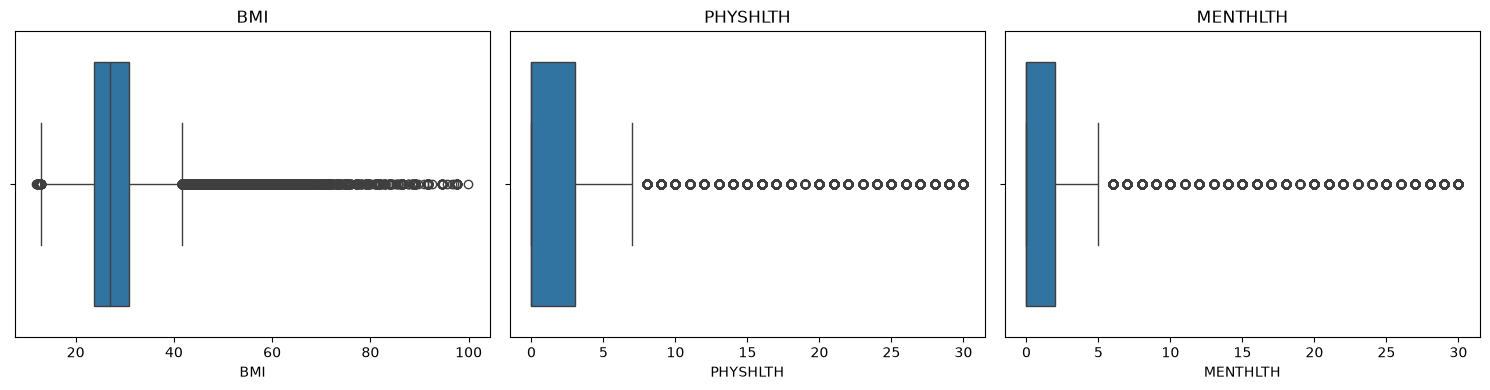

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, numeric_cols):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

**What we see:**
- `PHYSHLTH` and `MENTHLTH` are between 0 and 30, so all values are possible. Many people have 30 bad days, which is real (chronically ill people).
- `BMI` goes from 12 to almost 100. A BMI above ~80 is extremely rare and almost certainly an error in the reported weight or height.

The IQR rule flags many BMI values, but most of them are real:

In [23]:
q1, q3 = df['BMI'].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f'IQR limits: {low:.1f} - {high:.1f}')
print('values outside IQR limits:', ((df['BMI'] < low) | (df['BMI'] > high)).sum())
print('BMI < 12 or > 80         :', ((df['BMI'] < 12) | (df['BMI'] > 80)).sum())

IQR limits: 13.0 - 41.7
values outside IQR limits: 13698
BMI < 12 or > 80         : 509


**Decision:**
- **Impossible** values (BMI < 12 or > 80) → `NaN`. They will be imputed like the other missing values.
- **Extreme but possible** values (BMI 45–80) → **keep**. In health data a BMI of 50 is real, and obesity is strongly linked to diabetes, so these people are important.
- We use **fixed medical limits**, not percentiles. A percentile is computed from the data, so clipping by percentiles would have to be fitted on the training set only.

In [24]:
df.loc[(df['BMI'] < 12) | (df['BMI'] > 80), 'BMI'] = np.nan
df['BMI'].describe()

count    403956.000000
mean         27.966873
std           6.326068
min          12.020000
25%          23.730000
50%          26.940000
75%          30.900000
max          79.930000
Name: BMI, dtype: float64

## Step 8 — Class balance of the target

**Why:** if 85% of people are "No", a model that always says "No" gets 84% accuracy and is still useless.

target
0    375686
2     57253
1      7690
Name: count, dtype: int64

target
0    0.853
2    0.130
1    0.017
Name: proportion, dtype: float64


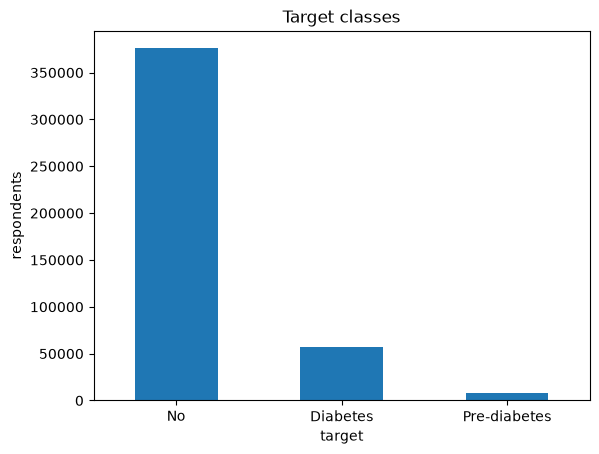

In [25]:
print(df['target'].value_counts())
print()
print(df['target'].value_counts(normalize=True).round(3))

ax = df['target'].map({0: 'No', 1: 'Pre-diabetes', 2: 'Diabetes'}).value_counts().plot.bar(rot=0)
ax.set_title('Target classes')
ax.set_ylabel('respondents')
plt.show()

**Decision (applied later):**
- `stratify=y` in `train_test_split` (mandatory), so train and test keep the same class proportions.
- On the **training set only**: `class_weight='balanced'`, undersampling or SMOTE.
- Evaluate with **recall, F1 (macro), ROC-AUC**, not just accuracy.
- Pre-diabetes is only ~2% of the data and will be the hardest class. If results are bad, a binary problem (diabetes vs. no diabetes) is a fair alternative.

## Step 9 — Features vs. target

**Why:** check that the features actually help, and catch leakage we missed. A feature that predicts the target almost perfectly is suspicious.

### 9a — Numeric features: mean per class

In [26]:
df.groupby('target')[numeric_cols].mean().round(2)

,BMI,PHYSHLTH,MENTHLTH
target,,,
0,27.36,3.65,3.10
1,30.49,6.69,4.74
2,31.59,8.26,4.49


### 9b — Categorical features: rate of each class per category

`normalize='index'` gives percentages per row: "among people with high blood pressure, how many have diabetes?"

In [27]:
for c in ['_RFHYPE5', 'GENHLTH', '_AGEG5YR']:
    display(pd.crosstab(df[c], df['target'], normalize='index').round(3))

target,0,1,2
_RFHYPE5,,,
1.0,0.935,0.011,0.054
2.0,0.732,0.027,0.241


target,0,1,2
GENHLTH,,,
1.0,0.969,0.007,0.024
2.0,0.922,0.013,0.065
3.0,0.824,0.021,0.155
4.0,0.691,0.030,0.278
5.0,0.615,0.029,0.356


target,0,1,2
_AGEG5YR,,,
1.0,0.986,0.004,0.009
2.0,0.980,0.005,0.014
3.0,0.971,0.007,0.023
4.0,0.951,0.009,0.040
5.0,0.929,0.010,0.061
6.0,0.899,0.016,0.085
7.0,0.870,0.017,0.113
8.0,0.844,0.018,0.138
9.0,0.806,0.022,0.172


### 9c — Strength of each feature, and leakage check

In [28]:
strength = df[features].corrwith(df['target'], method='spearman').abs().sort_values(ascending=False)
strength.round(3)

_RFHYPE5    0.282
GENHLTH     0.281
BMI         0.232
DIFFWALK    0.228
_AGEG5YR    0.212
_RFCHOL     0.210
_MICHD      0.183
HAVARTH3    0.173
PHYSHLTH    0.160
_INCOMG     0.144
_CHOLCHK    0.133
CHCKIDNY    0.132
_TOTINDA    0.113
CHCCOPD1    0.111
CVDSTRK3    0.110
_EDUCAG     0.109
ADDEPEV2    0.078
ASTHMA3     0.059
_RFDRHV5    0.055
_RACEGR3    0.052
_VEGLT1     0.047
_SMOKER3    0.046
HLTHPLN1    0.039
MENTHLTH    0.038
_FRTLT1     0.030
MEDCOST     0.022
SEX         0.014
MARITAL     0.008
dtype: float64

**Result:** the strongest features are general health, high blood pressure, BMI, age, walking difficulty and high cholesterol. This matches medical knowledge.
No feature is close to 1, so there is **no sign of leakage**.

### 9d — Constant / near-constant columns

In [29]:
print(df[features].nunique().sort_values().head())
top_share = df[features].apply(lambda s: s.value_counts(normalize=True).iloc[0])
print()
print('columns where one value is more than 95% of rows:')
print(top_share[top_share > 0.95])

ADDEPEV2    2
HLTHPLN1    2
_VEGLT1     2
_FRTLT1     2
_RFDRHV5    2
dtype: int64

columns where one value is more than 95% of rows:
CVDSTRK3    0.958556
CHCKIDNY    0.964438
dtype: float64


**Decision:** no constant column (every feature has at least 2 values). `Stroke` (`CVDSTRK3`) and `KidneyDisease` (`CHCKIDNY`) are "no" for ~96% of people, but they are rare diseases, not useless columns, and both are linked to diabetes (Step 9c). We keep them.

## Step 10 — Encoding

**Why:** BRFSS uses `1 = Yes, 2 = No`. A model would read "No" as "twice as much as Yes". We convert binary columns to `1 = Yes, 0 = No`. This is a fixed mapping (nothing is learned), so it is safe before the split.

**Careful with the direction:**
- Raw questions (`CVDSTRK3`, `DIFFWALK`, `HLTHPLN1`…) and `_MICHD`, `_TOTINDA`, `_FRTLT1`, `_VEGLT1`: `1 = yes`, `2 = no`
- Risk flags `_RF...` (`_RFHYPE5`, `_RFCHOL`, `_RFDRHV5`): `1 = no`, `2 = yes` (the opposite!)
- `SEX`: `1 = male`, `2 = female`

In [30]:
risk_flags = ['_RFHYPE5', '_RFCHOL', '_RFDRHV5']
yes_no_cols = [c for c in binary_cols if c not in risk_flags + ['SEX']]

for c in yes_no_cols:
    df[c] = df[c].map({1: 1, 2: 0})
for c in risk_flags:
    df[c] = df[c].map({1: 0, 2: 1})
df['SEX'] = df['SEX'].map({1: 1, 2: 0})   # 1 = male, 0 = female

df[binary_cols].describe().loc[['min', 'max', 'mean']].round(2)

,DIFFWALK,_RFHYPE5,_RFCHOL,CVDSTRK3,_MICHD,CHCKIDNY,CHCCOPD1,HAVARTH3,ADDEPEV2,ASTHMA3,_TOTINDA,_RFDRHV5,_FRTLT1,_VEGLT1,HLTHPLN1,MEDCOST,SEX
min,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00
max,1.00,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00
mean,0.17,0.4,0.42,0.04,0.09,0.04,0.08,0.34,0.19,0.13,0.73,0.05,0.62,0.79,0.93,0.1,0.42


**Readable names:** now that the codes are decoded, we rename the columns so the rest of the project is easier to read.

In [31]:
rename = {
    'GENHLTH': 'GenHealth', 'PHYSHLTH': 'PhysHealthDays', 'MENTHLTH': 'MentHealthDays', 'DIFFWALK': 'DiffWalk',
    '_RFHYPE5': 'HighBP', '_RFCHOL': 'HighChol', '_CHOLCHK': 'CholCheck',
    'CVDSTRK3': 'Stroke', '_MICHD': 'HeartDisease', 'CHCKIDNY': 'KidneyDisease', 'CHCCOPD1': 'COPD',
    'HAVARTH3': 'Arthritis', 'ADDEPEV2': 'Depression', 'ASTHMA3': 'Asthma',
    '_SMOKER3': 'Smoker', '_TOTINDA': 'PhysActivity', '_RFDRHV5': 'HeavyDrinker',
    '_FRTLT1': 'Fruits', '_VEGLT1': 'Veggies', 'HLTHPLN1': 'HealthPlan', 'MEDCOST': 'NoDocBcCost',
    'SEX': 'Male', '_AGEG5YR': 'AgeGroup', '_EDUCAG': 'Education', '_INCOMG': 'Income',
    '_RACEGR3': 'Race', 'MARITAL': 'Marital',
}
df = df.rename(columns=rename)

numeric_cols = [rename.get(c, c) for c in numeric_cols]
ordinal_cols = [rename.get(c, c) for c in ordinal_cols]
nominal_cols = [rename.get(c, c) for c in nominal_cols]
binary_cols  = [rename.get(c, c) for c in binary_cols]
features     = [rename.get(c, c) for c in features]

df.head()

,GenHealth,PhysHealthDays,MentHealthDays,DiffWalk,HighBP,HighChol,CholCheck,Stroke,HeartDisease,KidneyDisease,COPD,Arthritis,Depression,Asthma,Smoker,PhysActivity,HeavyDrinker,Fruits,Veggies,HealthPlan,NoDocBcCost,Male,AgeGroup,Education,Income,Race,Marital,DIABETE3,target,BMI
0,5.0,15.0,18.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,3.0,0.0,0.0,0.0,1.0,1.0,0.0,0,9.0,2.0,2.0,1.0,1.0,3.0,0,40.18
1,3.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0,7.0,4.0,1.0,1.0,2.0,3.0,0,25.09
2,4.0,15.0,0.0,NaN,0.0,1.0,1.0,1.0,NaN,0.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0,0.0,0,11.0,2.0,NaN,1.0,2.0,3.0,0,22.04
3,5.0,30.0,30.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,4.0,0.0,0.0,1.0,0.0,1.0,1.0,0,9.0,2.0,5.0,1.0,1.0,3.0,0,28.19
4,5.0,20.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4.0,0.0,0.0,NaN,1.0,1.0,0.0,0,9.0,3.0,NaN,1.0,1.0,3.0,0,24.37


**Rest of the encoding plan** (done in the pipeline after the split, see Step 11):
- **Ordinal** (`GenHealth`, `AgeGroup`, `Education`, `Income`, `Smoker`, `CholCheck`): keep as ordered integers.
- **Nominal** (`Race`, `Marital`): one-hot encoding with `OneHotEncoder`. Each category becomes its own 0/1 column, so the model does not think "Race 5 > Race 1".
- **Scaling** (`StandardScaler`): only needed for models like logistic regression, KNN or SVM. Trees do not need it.

## Step 11 — Final checks, save and split

### 11a — Checklist

Each `assert` stops the notebook with an error if a check fails.

In [32]:
codes_left = {'PhysHealthDays': [77, 88, 99], 'MentHealthDays': [77, 88, 99],
              'GenHealth': [7, 9], 'AgeGroup': [14], 'Income': [9], 'Education': [9]}

assert df['target'].notna().all() and set(df['target'].unique()) == {0, 1, 2}   # valid target only
assert not set(admin_cols + leakage_cols) & set(df.columns)                       # no admin / leakage columns
assert not set(redundant) & set(df.columns)                                       # no redundant columns
assert all(not df[c].isin(v).any() for c, v in codes_left.items())                # no special codes left
assert df['BMI'].dropna().between(12, 80).all()                                   # no impossible BMI
assert df[binary_cols].isin([0, 1, np.nan]).all().all()                           # binary columns are 0/1
assert len(df.select_dtypes(exclude='number').columns) == 0                       # all numeric

print('All checks passed')
print(df.shape)
print('remaining missing values:', df[features].isna().sum().sum(), '(will be imputed in the pipeline)')

All checks passed
(440629, 30)
remaining missing values: 437729 (will be imputed in the pipeline)


### 11b — Save the clean dataset

So we don't have to redo all of this each time. (`*.csv` is in `.gitignore`, so the file stays out of Git.)

In [33]:
df.to_csv('diabetes_clean_2015.csv', index=False)
print('saved', df.shape)

saved (440629, 30)


### 11c — Split

`stratify=y` keeps the same class proportions in train and test. `random_state=42` gives the same split every time.

In [34]:
from sklearn.model_selection import train_test_split

X = df[features]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print('train:', X_train.shape, ' test:', X_test.shape)
pd.DataFrame({'train': y_train.value_counts(normalize=True),
              'test':  y_test.value_counts(normalize=True)}).round(3)

train: (352503, 28)  test: (88126, 28)


,train,test
target,,
0,0.853,0.853
2,0.130,0.130
1,0.017,0.017


### 11d — Preprocessing pipeline (fitted on the training set only)

This is where the things that **learn** from the data go: the imputer learns medians / most frequent values, the scaler learns means and standard deviations, the encoder learns the categories.

- `fit_transform(X_train)`: learn **and** apply on the training set
- `transform(X_test)`: only **apply** what was learned on train. The test set stays "unseen".

Later, put this `preprocess` and a model together in one `Pipeline`, so cross-validation also respects this rule.

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale',  StandardScaler())]), numeric_cols),
    ('ord', SimpleImputer(strategy='most_frequent'), ordinal_cols),
    ('bin', SimpleImputer(strategy='most_frequent'), binary_cols),
    ('nom', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), nominal_cols),
])

X_train_prep = preprocess.fit_transform(X_train)   # learn on train
X_test_prep  = preprocess.transform(X_test)        # apply to test

print('train:', X_train_prep.shape, ' test:', X_test_prep.shape)
print('missing values left:', np.isnan(X_train_prep).sum(), np.isnan(X_test_prep).sum())

train: (352503, 37)  test: (88126, 37)
missing values left: 0 0


## Summary

| # | Step | What we found | What we did |
|---|---|---|---|
| 0 | Load | 441,456 × 330 | kept `raw` untouched |
| 1 | Target | ~800 invalid labels | dropped them; 3 classes (No / Pre / Diabetes) |
| 2 | Columns | admin, empty and leakage columns | dropped; kept a list of health features |
| 4 | Special codes | ~420k hidden missing values (7/9/77/99/14), `88` = 0 days | decoded column by column |
| 3 | Redundancy | 9 raw/computed pairs | kept the computed `_` version |
| 5 | Missing values | income 18%, high cholesterol 14% (informative), others small | dropped rows > 50% empty; impute in pipeline |
| 6 | Types | `_BMI5` × 100 | `BMI = _BMI5 / 100`; numeric / ordinal / binary / nominal lists |
| 7 | Outliers | BMI up to ~100 | BMI outside 12–80 → NaN; kept real extremes |
| 8 | Class balance | 85% No / 2% Pre / 13% Diabetes | `stratify=y`; balance on train later |
| 9 | Feature vs target | strong: GenHealth, HighBP, BMI, Age | no leakage found |
| 10 | Encoding | `1 = yes, 2 = no` codes | binary → 0/1, readable names; one-hot in pipeline |
| 11 | Final | all checks pass | saved `diabetes_clean_2015.csv`, split 80/20 |

**Next step:** modelling. Put `preprocess` + a model (logistic regression with `class_weight='balanced'`, random forest, gradient boosting…) in a `Pipeline`, and evaluate with recall, macro F1 and ROC-AUC.